In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("cleaned_final.csv")
df['target_epoch'] = pd.to_datetime(df['target_epoch'])

df = df[df['target_epoch'] < '2025-11-20'].reset_index(drop=True)

targets = ['x_error', 'y_error', 'z_error']
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx]
test_df  = df.iloc[split_idx:]

def report(name, pred):
    resid = test_df[targets].values - pred
    e = np.linalg.norm(resid, axis=1)
    print(f"{name:25s} średnia {e.mean():.3f} | mediana {np.median(e):.3f} | p90 {np.percentile(e, 90):.3f}")
    print(resid[:5].round(2))
    print(np.linalg.norm(resid[:5], axis=1).round(2))

report("SGP4 (brak korekty)", np.zeros((len(test_df), 3)))

SGP4 (brak korekty)       średnia 3.777 | mediana 2.290 | p90 9.474
[[ 4.53  1.22 -1.42]
 [ 5.85  1.62 -1.16]
 [-1.02  0.43  1.3 ]
 [-1.23  0.19  0.81]
 [-1.14  0.    0.23]]
[4.9  6.18 1.71 1.48 1.17]


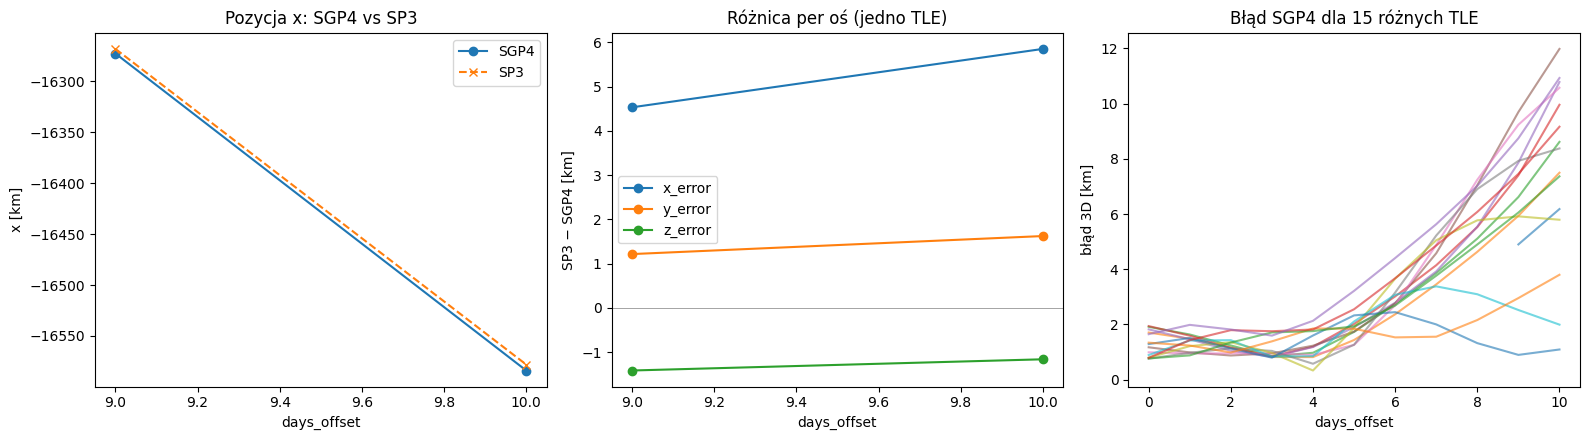

In [7]:
d = test_df.copy()
d['sp3_x'] = d['x'] + d['x_error']
d['sp3_y'] = d['y'] + d['y_error']
d['sp3_z'] = d['z'] + d['z_error']
d['err3d'] = np.linalg.norm(d[targets].values, axis=1)

one_tle = d['tle_epoch'].iloc[0]
s = d[d['tle_epoch'] == one_tle].sort_values('days_offset')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. pozycje: SGP4 i SP3 (oś x) w kolejnych dniach
ax[0].plot(s['days_offset'], s['x'],     'o-', label='SGP4')
ax[0].plot(s['days_offset'], s['sp3_x'], 'x--', label='SP3')
ax[0].set_xlabel('days_offset'); ax[0].set_ylabel('x [km]')
ax[0].set_title('Pozycja x: SGP4 vs SP3'); ax[0].legend()

# 2. różnica SP3 - SGP4 per oś (to są dokładnie x_error, y_error, z_error)
for c in targets:
    ax[1].plot(s['days_offset'], s[c], 'o-', label=c)
ax[1].axhline(0, color='gray', lw=0.5)
ax[1].set_xlabel('days_offset'); ax[1].set_ylabel('SP3 − SGP4 [km]')
ax[1].set_title('Różnica per oś (jedno TLE)'); ax[1].legend()

# 3. długość 3D błędu dla kilku TLE: każda linia to jedno TLE
for tle, g in list(d.groupby('tle_epoch'))[:15]:
    g = g.sort_values('days_offset')
    ax[2].plot(g['days_offset'], g['err3d'], alpha=0.6)
ax[2].set_xlabel('days_offset'); ax[2].set_ylabel('błąd 3D [km]')
ax[2].set_title('Błąd SGP4 dla 15 różnych TLE')

plt.tight_layout(); plt.show()

In [10]:
med = train_df.groupby('days_offset')[targets].median()
pred_med = med.loc[test_df['days_offset'].values].values
report("SGP4 (brak korekty)", np.zeros((len(test_df), 3)))
report("mediana per offset",  pred_med)
# i model, dla porównania w tej samej formie
# report("MLP", preds_km)

SGP4 (brak korekty)       średnia 3.777 | mediana 2.290 | p90 9.474
[[ 4.53  1.22 -1.42]
 [ 5.85  1.62 -1.16]
 [-1.02  0.43  1.3 ]
 [-1.23  0.19  0.81]
 [-1.14  0.    0.23]]
[4.9  6.18 1.71 1.48 1.17]
mediana per offset        średnia 3.797 | mediana 2.337 | p90 9.464
[[ 3.73  1.14 -0.73]
 [ 4.77  1.48 -0.5 ]
 [-0.98  0.24  1.4 ]
 [-1.17  0.07  0.92]
 [-1.1  -0.02  0.27]]
[3.97 5.02 1.73 1.49 1.14]
